# Klasifikasi Multi-label: A10, A11, dan A12

Di notebook ini aku bahas tiga dataset multi-label: A10 arXiv (klasifikasi topik paper), A11 `career_multilabel_dataset`, dan A12 `drone_communication_dataset`.

Definisi multi-label: satu sampel bisa punya lebih dari satu label sekaligus, dan labelnya tidak saling meniadakan. Biasanya direpresentasikan sebagai vektor 0/1 (multi-hot).

Untuk menjalankan, taruh `archive (10).zip`, `archive (11).zip`, dan `archive (12).zip` di folder yang sama dengan notebook ini, atau ubah `DATA_DIR`. CSV dibaca langsung dari zip.

Skor 1-5 di bawah adalah penilaianku sendiri, dan baseline-nya model default tanpa tuning, jadi cukup sebagai gambaran kasar.

In [1]:
import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import hamming_loss, accuracy_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

SOURCES = {
    "A10 arXiv":  (10, "train.csv"),
    "A11 career": (11, "career_multilabel_dataset.csv"),
    "A12 drone":  (12, "drone_communication_dataset.csv"),
}

SEED = 42
# Folder tempat file zip berada. Bisa diubah, atau set environment variable DATA_DIR.
DATA_DIR = os.environ.get("DATA_DIR", ".")

def find_zip(n):
    # cocok dengan 'archive (4).zip', 'archive__4_.zip', dst., tapi tidak 'archive (14).zip'
    pat = re.compile(rf"archive\D*{n}\D*\.zip$", re.I)
    for f in sorted(os.listdir(DATA_DIR)):
        if pat.search(f):
            return os.path.join(DATA_DIR, f)
    raise FileNotFoundError(f"Zip arsip {n} tidak ditemukan di DATA_DIR={DATA_DIR!r}")

def read_from_zip(n, member):
    with zipfile.ZipFile(find_zip(n)) as z:
        with z.open(member) as f:
            return pd.read_csv(f)

data = {k: read_from_zip(n, m) for k, (n, m) in SOURCES.items()}
print({k: v.shape for k, v in data.items()})

{'A10 arXiv': (20972, 9), 'A11 career': (2000, 25), 'A12 drone': (45289, 35)}


## 1. Gambaran umum data

In [2]:
rows = []
for k, df in data.items():
    rows.append({"Dataset": k, "Baris": df.shape[0], "Kolom": df.shape[1],
                 "Nilai kosong": int(df.isna().sum().sum()), "Baris duplikat": int(df.duplicated().sum())})
pd.DataFrame(rows).set_index("Dataset")

,Baris,Kolom,Nilai kosong,Baris duplikat
Dataset,,,,
A10 arXiv,20972,9,0,0
A11 career,2000,25,0,0
A12 drone,45289,35,0,0


## 2. Target

Bentuk target ketiganya beda-beda, jadi pertama-tama perlu disamakan dulu ke matriks multi-hot:

- **A10 arXiv**: sudah berupa 6 kolom 0/1 untuk topik (Computer Science, Physics, Mathematics, Statistics, Quantitative Biology, Quantitative Finance). Inputnya teks (`TITLE` + `ABSTRACT`). Di arsipnya ada juga `test.csv`, tapi tanpa label, jadi yang dipakai hanya `train.csv`.
- **A11 career**: targetnya 3 kolom kategorikal `recommended_job_1..3`. Aku ubah ke multi-hot pakai `MultiLabelBinarizer`.
- **A12 drone**: 8 kolom 0/1 `label_*` (normal plus 7 jenis serangan).

In [3]:
JOB_COLS = ["recommended_job_1", "recommended_job_2", "recommended_job_3"]
ARXIV_LABELS = ["Computer Science", "Physics", "Mathematics", "Statistics", "Quantitative Biology", "Quantitative Finance"]
DRONE_LABELS = [c for c in data["A12 drone"].columns if c.startswith("label_")]

Y = {}
Y["A10 arXiv"] = data["A10 arXiv"][ARXIV_LABELS].astype(int).reset_index(drop=True)
mlb = MultiLabelBinarizer()
Y["A11 career"] = pd.DataFrame(mlb.fit_transform(data["A11 career"][JOB_COLS].values), columns=mlb.classes_)
Y["A12 drone"] = data["A12 drone"][DRONE_LABELS].astype(int).reset_index(drop=True)

def ml_stats(Yd):
    n = Yd.sum(axis=1)
    return {"Sampel": len(Yd), "Jumlah label": Yd.shape[1],
            "Rata-rata label/sampel": n.mean(), "Std label/sampel": n.std(),
            "% sampel >1 label": (n > 1).mean() * 100, "% sampel 0 label": (n == 0).mean() * 100,
            "Kombinasi label unik": Yd.drop_duplicates().shape[0],
            "Label density": n.mean() / Yd.shape[1],
            "Imbalance (label terbanyak / tersedikit)": Yd.sum().max() / Yd.sum().min()}

ml_table = pd.DataFrame({k: ml_stats(v) for k, v in Y.items()})
ml_table.round(3)

,A10 arXiv,A11 career,A12 drone
Sampel,20972.000,2000.000,45289.000
Jumlah label,6.000,13.000,8.000
Rata-rata label/sampel,1.252,3.000,0.457
Std label/sampel,0.461,0.000,0.653
% sampel >1 label,24.051,100.000,7.123
% sampel 0 label,0.000,0.000,62.322
Kombinasi label unik,24.000,110.000,114.000
Label density,0.209,0.231,0.057
Imbalance (label terbanyak / tersedikit),34.514,36.200,4.825


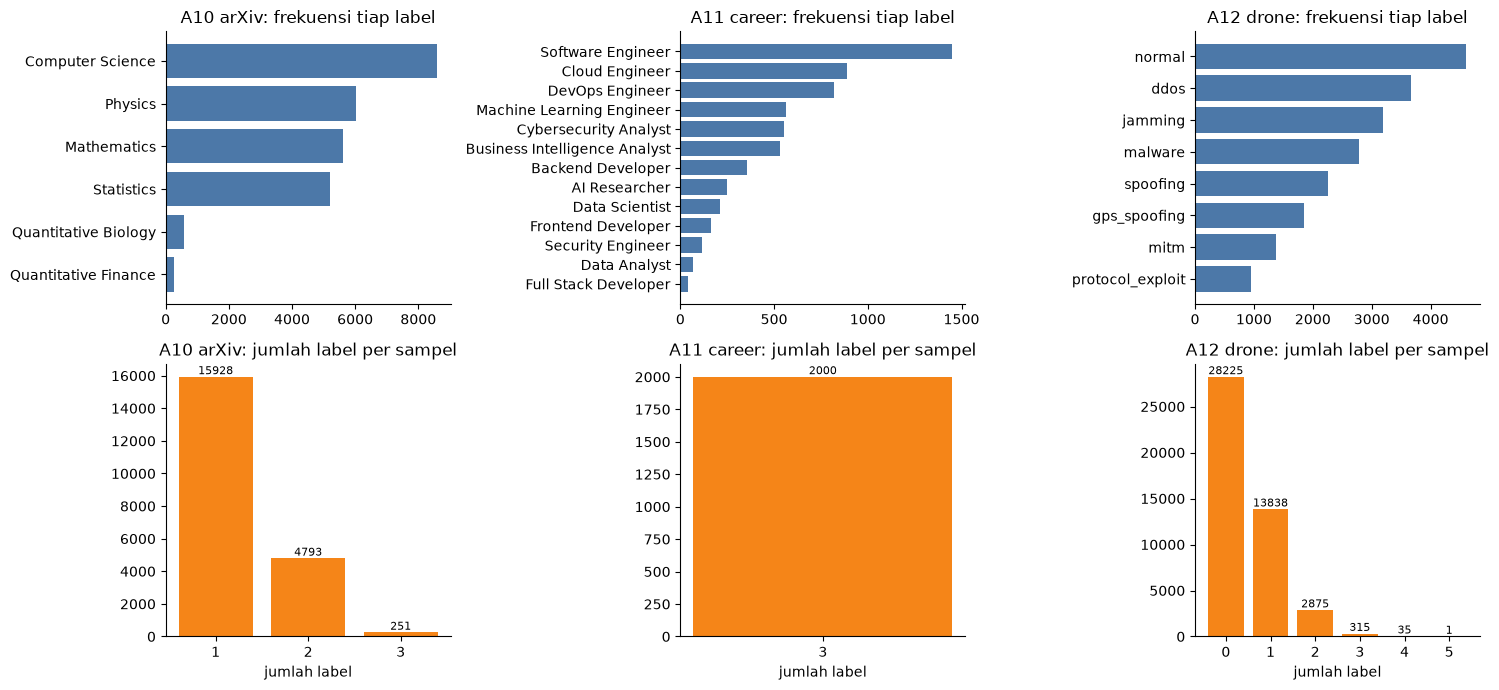

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for j, (k, Yd) in enumerate(Y.items()):
    s = Yd.sum().sort_values()
    axs[0, j].barh([x.replace("label_", "") for x in s.index], s.values, color="#4C78A8")
    axs[0, j].set_title(f"{k}: frekuensi tiap label")
    n = Yd.sum(axis=1).value_counts().sort_index()
    axs[1, j].bar(n.index.astype(str), n.values, color="#F58518")
    axs[1, j].set_title(f"{k}: jumlah label per sampel"); axs[1, j].set_xlabel("jumlah label")
    for i, v in enumerate(n.values): axs[1, j].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

## 3. Hal yang perlu diwaspadai

Ada dua hal yang menurutku janggal:

- **A11**: tiap baris selalu punya tepat 3 pekerjaan (std label per sampel = 0) dan urutannya berperingkat. Ini lebih mirip top-3 ranking ketimbang multi-label sungguhan.
- **A12**: sebagian besar baris tidak punya label sama sekali, dan label `normal` bisa muncul bersamaan dengan label serangan. Kita hitung seberapa sering.

In [5]:
d = data["A12 drone"]
att = [c for c in DRONE_LABELS if c != "label_normal"]
has_att = d[att].sum(axis=1) > 0
print("Baris tanpa label apa pun            :", int((d[DRONE_LABELS].sum(axis=1) == 0).sum()), f"({(d[DRONE_LABELS].sum(axis=1) == 0).mean():.1%})")
print("Baris 'normal' saja                  :", int(((d.label_normal == 1) & ~has_att).sum()))
print("Baris 'normal' DAN ada label serangan:", int(((d.label_normal == 1) & has_att).sum()), "(janggal secara logika)")
print("Baris dengan >=2 label               :", int((d[DRONE_LABELS].sum(axis=1) >= 2).sum()))

Baris tanpa label apa pun            : 28225 (62.3%)
Baris 'normal' saja                  : 3233
Baris 'normal' DAN ada label serangan: 1375 (janggal secara logika)
Baris dengan >=2 label               : 3226


## 4. Baseline model

Untuk multi-label aku pakai hold-out 80/20. A10 dimodelkan dengan TF-IDF + Logistic Regression one-vs-rest, sedangkan A11 dan A12 pakai Random Forest yang bisa langsung menangani banyak label sekaligus.

In [6]:
X_ml = {}

# A10: teks
d = data["A10 arXiv"]
X_ml["A10 arXiv"] = (d["TITLE"].fillna("") + ". " + d["ABSTRACT"].fillna("")).str.replace(r"\s+", " ", regex=True)

# A11: one-hot untuk fitur kategorikal
c_ = data["A11 career"]
X_ml["A11 career"] = pd.get_dummies(c_.drop(columns=JOB_COLS), dtype=float)

# A12: buang timestamp, parse koordinat GPS, one-hot untuk fitur kategorikal
d = data["A12 drone"]
Xd = d.drop(columns=["timestamp"] + DRONE_LABELS)
gps = Xd["drone_gps_coordinates"].str.strip("()").str.split(",", expand=True).astype(float)
Xd = Xd.drop(columns="drone_gps_coordinates")
Xd["gps_lat"], Xd["gps_lon"] = gps[0].values, gps[1].values
X_ml["A12 drone"] = pd.get_dummies(Xd, dtype=float)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_ml["A12 drone"].dtypes)

def eval_ml(Yt, Yp):
    return {"Hamming loss": hamming_loss(Yt, Yp), "Subset accuracy": accuracy_score(Yt, Yp),
            "Micro-F1": f1_score(Yt, Yp, average="micro", zero_division=0),
            "Macro-F1": f1_score(Yt, Yp, average="macro", zero_division=0)}

def make_model(key):
    if key == "A10 arXiv":
        return make_pipeline(
            TfidfVectorizer(max_features=30000, stop_words="english", sublinear_tf=True),
            OneVsRestClassifier(LogisticRegression(C=4, class_weight="balanced", max_iter=1000), n_jobs=-1))
    return RandomForestClassifier(200, random_state=SEED, n_jobs=-1)   # mendukung multi-output secara native

res_ml, per_label = {}, {}
for key in Y:
    Xtr, Xte, Ytr, Yte = train_test_split(X_ml[key], Y[key], test_size=0.2, random_state=SEED)
    m = make_model(key).fit(Xtr, Ytr)
    Yp = m.predict(Xte)
    P = m.predict_proba(Xte)
    if isinstance(P, list):                      # RandomForest multi-output -> list per label
        P = np.column_stack([p[:, 1] for p in P])
    auc = [roc_auc_score(Yte.iloc[:, j], P[:, j]) for j in range(Yte.shape[1])]
    r = eval_ml(Yte, Yp)
    r["Macro ROC-AUC"] = float(np.mean(auc))
    r["Hamming loss (tebak semua 0)"] = hamming_loss(Yte, np.zeros_like(Yte))
    res_ml[key] = r
    names = [x.replace("label_", "") for x in Y[key].columns]
    per_label[key] = pd.DataFrame({"F1": f1_score(Yte, Yp, average=None, zero_division=0), "ROC-AUC": auc}, index=names)

res_ml = pd.DataFrame(res_ml).T
display(res_ml.round(3))

,Hamming loss,Subset accuracy,Micro-F1,Macro-F1,Macro ROC-AUC,Hamming loss (tebak semua 0)
A10 arXiv,0.077,0.649,0.825,0.781,0.956,0.211
A11 career,0.040,0.578,0.905,0.631,0.978,0.231
A12 drone,0.057,0.619,0.000,0.000,0.493,0.057


In [7]:
for k, s in per_label.items():
    print(f"\n{k}: metrik per label")
    print(s.round(3).sort_values("ROC-AUC", ascending=False).to_string())


A10 arXiv: metrik per label
                         F1  ROC-AUC
Physics               0.877    0.975
Quantitative Finance  0.809    0.975
Mathematics           0.810    0.953
Quantitative Biology  0.559    0.952
Statistics            0.791    0.945
Computer Science      0.840    0.936

A11 career: metrik per label
                                  F1  ROC-AUC
Software Engineer              0.997    1.000
Data Analyst                   0.462    0.998
Cybersecurity Analyst          0.957    0.998
DevOps Engineer                0.989    0.997
Cloud Engineer                 0.981    0.995
Business Intelligence Analyst  0.949    0.994
Data Scientist                 0.610    0.994
Frontend Developer             0.258    0.990
Backend Developer              0.696    0.989
Machine Learning Engineer      0.914    0.987
AI Researcher                  0.303    0.957
Security Engineer              0.091    0.938
Full Stack Developer           0.000    0.882

A12 drone: metrik per label
         

Beberapa catatan untuk membaca tabel di atas. Hamming loss bisa kelihatan kecil hanya karena kebanyakan label bernilai 0, makanya aku sertakan pembanding "tebak semua 0". Subset accuracy sangat ketat karena seluruh vektor label harus tepat. Macro-F1 menunjukkan seberapa buruk model menangani label yang jarang.

Yang paling mencolok ada di A12 drone: Micro-F1 dan Macro-F1 nol, dan Hamming loss-nya sama persis dengan menebak semua 0. ROC-AUC per label juga sekitar 0,5, setara tebakan acak. Jadi ini bukan soal threshold atau imbalance. Dengan fitur yang ada, label A12 hampir tidak bisa dipelajari. Untuk memastikan, kita lihat korelasi fitur dengan label.

In [8]:
# Apakah ada fitur A12 yang berhubungan dengan salah satu label?
Xa = X_ml["A12 drone"]
cor = pd.concat([Xa, Y["A12 drone"]], axis=1).corr()[DRONE_LABELS].drop(index=DRONE_LABELS).abs().max(axis=1).sort_values(ascending=False)
print("Korelasi absolut maksimum (fitur vs label apa pun), 5 teratas:")
print(cor.head(5).round(3).to_string())

Korelasi absolut maksimum (fitur vs label apa pun), 5 teratas:
temporal_patterns                0.017
network_traffic_volume           0.011
communication_protocol_Wi-Fi     0.010
communication_protocol_LoRa      0.010
communication_protocol_ZigBee    0.010


## 5. Apakah benar-benar multi-label?

In [9]:
def check_row(key):
    Yd = Y[key]; n = Yd.sum(axis=1)
    kolom = 3 if key == "A11 career" else Yd.shape[1]
    return {"Kolom target asli": kolom, "Kelas/label": Yd.shape[1],
            "Rata-rata label/sampel": n.mean(), "Std label/sampel": n.std(),
            "% sampel >1 label": (n > 1).mean() * 100,
            "Lolos (ada multi-label & jumlah label bervariasi)": bool((n > 1).any() and n.std() > 0)}

verif = pd.DataFrame({k: check_row(k) for k in Y}).T
verif

,Kolom target asli,Kelas/label,Rata-rata label/sampel,Std label/sampel,% sampel >1 label,Lolos (ada multi-label & jumlah label bervariasi)
A10 arXiv,6,6,1.252479,0.461173,24.051116,True
A11 career,3,13,3.0,0.0,100.0,False
A12 drone,8,8,0.456579,0.653096,7.123142,True


Hanya A11 yang tidak lolos kriteria multi-label yang ketat: jumlah label per sampel selalu 3 (tidak ada variasi), dan target aslinya kolom kategorikal berperingkat, bukan vektor multi-hot. A11 masih bisa dimodelkan sebagai multi-label setelah diubah, tapi bukan contoh yang murni.

| Dataset | Skor | Alasan |
|---|---|---|
| A10 arXiv | 5 | Multi-hot asli, jumlah label per sampel bervariasi (1-3), sampel banyak, tidak ada baris tanpa label, dan imbalance-nya berat tapi realistis. |
| A11 career | 3 | Targetnya 3 kolom kategorikal berperingkat dengan jumlah label tetap (selalu 3), dan harus diubah dulu ke multi-hot. |
| A12 drone | 4 | Multi-hot asli dengan 8 label, tapi sebagian besar baris tanpa label, `normal` bisa muncul bareng serangan, dan labelnya hampir tidak bisa diprediksi dari fitur (ROC-AUC sekitar 0,5). Skor ini hanya menilai struktur targetnya; sebagai bahan benchmark model, dataset ini lemah. |

In [10]:
SKOR = {"A10 arXiv": 5, "A11 career": 3, "A12 drone": 4}
fitur = {"A10 arXiv": "teks (TITLE + ABSTRACT)",
         "A11 career": data["A11 career"].shape[1] - 3,
         "A12 drone": data["A12 drone"].shape[1] - len(DRONE_LABELS)}
summary = pd.DataFrame({
    "Sampel": {k: len(Y[k]) for k in Y},
    "Fitur input": fitur,
    "Jumlah label": {k: Y[k].shape[1] for k in Y},
    "Imbalance (max/min)": {k: round(Y[k].sum().max() / Y[k].sum().min(), 2) for k in Y},
    "Micro-F1": {k: round(res_ml.loc[k, "Micro-F1"], 3) for k in Y},
    "Macro ROC-AUC": {k: round(res_ml.loc[k, "Macro ROC-AUC"], 3) for k in Y},
    "Skor kesesuaian": SKOR,
})
summary

,Sampel,Fitur input,Jumlah label,Imbalance (max/min),Micro-F1,Macro ROC-AUC,Skor kesesuaian
A10 arXiv,20972,teks (TITLE + ABSTRACT),6,34.51,0.825,0.956,5
A11 career,2000,22,13,36.20,0.905,0.978,3
A12 drone,45289,27,8,4.83,0.000,0.493,4


## 6. Kesimpulan

Yang paling pas mewakili multi-label adalah **A10 arXiv**: multi-hot asli, jumlah label per sampel bervariasi, sampelnya banyak, tidak ada baris kosong, dan labelnya memang bisa dipelajari (Micro-F1 sekitar 0,82, macro-AUC sekitar 0,96).

A12 drone ada di urutan kedua kalau dilihat dari strukturnya, tapi labelnya tidak terbaca dari fitur. Sebelum dipakai, sebaiknya dicek dulu bagaimana label itu dibuat, lalu diputuskan cara memperlakukan baris tanpa label dan kasus `normal` bersamaan dengan serangan. A11 career paling bawah karena sebenarnya top-3 ranking dengan jumlah label tetap; kalau dipakai, ubah ke multi-hot dan putuskan apakah urutan peringkat masih penting.

Soal pemodelan: neural network untuk multi-label biasanya memakai sigmoid per label dengan binary cross-entropy. Metrik yang cocok: Hamming loss, subset accuracy, micro dan macro F1, ditambah ROC-AUC per label. Label yang jarang (seperti Quantitative Biology di A10) butuh perhatian khusus, misalnya lewat class weight atau threshold per label.